# Case 3: The sign that flipped: what does it prove?
*Applies: Feature importance and its limits · Encoding categoricals; scaling numerics;
which models care (coefficients are compared only on scaled columns)*

The honest model from case 2 goes to the campaign review. The campaign head reads two
exhibits: the model's coefficients and an importance chart. Someone will point at the top
bar and say "so this is what drives deposits". This notebook finds out what each exhibit
can carry, starting from one column whose coefficient changes sign depending on who sits
beside it.

**Who needs the answer.** The campaign head, who will be tempted to act on the top bar, and
the senior ML engineer, who has to say what the chart proves before anyone acts on it.

**The questions on the way.** How closely do the rate columns move together? What happens to
`euribor3m`'s sign when its partners join? What does permutation importance rank? Why can a
single column's importance exceed the model's whole lift? Does a top rank prove a cause?
What is the audited feature set we hand to Thursday?

**You will be able to** show a coefficient's sign flip on real columns, compute permutation
importance column by column and by group, and say in one sentence what an importance chart
proves and what it does not.

**Search terms:** feature importance, permutation importance, multicollinearity, coefficient
sign flip, correlation is not causation.

## What does the pipeline give us again?
The week's shared code, the scorer and case 2's engineered `pdays` columns, so the honest
feature set is rebuilt exactly.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline every case notebook starts from: the same file, columns, split and baseline.
import io, zipfile, pathlib, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
# Joined on Wednesday from other feeds: the call log and the economic indicators.
CALL_LOG = ["duration"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

CALL_RS, MISSED_RS = 40, 1200            # Tuesday's costs: one call, one missed buyer's margin
THRESHOLD = CALL_RS / (CALL_RS + MISSED_RS)

def score(columns, tr=None, va=None):
    """Fit on training rows, score validation rows, and return the numbers the day quotes."""
    tr = train if tr is None else tr
    va = val if va is None else va
    ytr, yva = (tr["y"] == "yes").astype(int), (va["y"] == "yes").astype(int)
    model = logistic(columns, tr).fit(tr[columns], ytr)
    p = model.predict_proba(va[columns])[:, 1]
    tn, fp, fn, tp = confusion_matrix(yva, (p >= 0.5).astype(int)).ravel()
    tn2, fp2, fn2, tp2 = confusion_matrix(yva, (p >= THRESHOLD).astype(int)).ravel()
    top = yva.values[np.argsort(-p)[:1000]].sum()
    return {"columns": len(columns), "AUC": round(roc_auc_score(yva, p), 4),
            "accuracy": round(accuracy_score(yva, (p >= 0.5).astype(int)), 4),
            "TP": tp, "FP": fp, "FN": fn, "recall": round(tp / (tp + fn), 3),
            "bill_Rs": int(fp2 * CALL_RS + fn2 * MISSED_RS), "buyers_in_top_1000": int(top)}, model, p

bank = load_bank()
train, val, test = week_split(bank)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)
print(f"{len(bank):,} calls: train {len(train):,}, validation {len(val):,}, "
      f"test {len(test):,} (sealed until Friday)")
print(f"Base rate: {y_train.mean():.2%} of training calls ended in a deposit")

def engineer(df):
    """Wednesday's feature work on the bank's file: the 999 sentinel split into a flag and a number."""
    out = df.copy()
    out["never_contacted"] = (out["pdays"] == 999).astype(int)
    out["days_since_contact"] = out["pdays"].where(out["pdays"] != 999, 0)
    return out

bank = engineer(bank)
train, val, test = week_split(bank)
CUSTOMER = PROFILE + HISTORY
HONEST = CUSTOMER + ["never_contacted", "days_since_contact"] + ECONOMY

honest, honest_model, p_honest = score(HONEST)
print("honest validation AUC:", honest["AUC"])

41,188 calls: train 24,712, validation 8,238, test 8,238 (sealed until Friday)
Base rate: 11.27% of training calls ended in a deposit


honest validation AUC: 0.7955


## How closely do the rate columns move together?
Three of the five economic columns describe the same thing from different desks: the
employment variation rate, the three-month interbank rate and the number employed.

**Predict before you run.** The correlation between `euribor3m` and `emp.var.rate` is
(A) about 0.3; (B) about 0.6; (C) above 0.95.

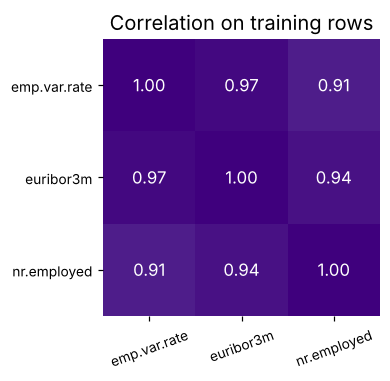

In [2]:
TRIO = ["emp.var.rate", "euribor3m", "nr.employed"]
corr = train[TRIO].corr().round(3)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.imshow(corr.values, cmap="Purples", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(TRIO, rotation=20, fontsize=9)
ax.set_yticks(range(3)); ax.set_yticklabels(TRIO, fontsize=9)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.values[i, j] > 0.6 else INK, fontsize=11)
ax.set_title("Correlation on training rows"); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.show()

**What happened.** C. `euribor3m` and `emp.var.rate` correlate at 0.97, and `nr.employed`
sits at 0.91 and 0.94 with them. When three columns move together this closely, the data
holds almost no row where one is high and another low, which is what a coefficient needs in
order to tell them apart.

## What happens to euribor3m's sign when its partners join?
Fit a logistic model on standardised columns, so each coefficient is the change in log-odds
for one standard deviation, with a penalty so weak it does not matter (C = 1,000,000).
First `euribor3m` alone, then with `nr.employed`, then with both partners, then inside the
full honest model.

**Predict before you run.** Alone, `euribor3m` has a negative coefficient: higher rates,
fewer deposits. With both partners beside it, its coefficient (A) stays negative and
shrinks; (B) turns positive; (C) goes to exactly zero.

In [3]:
Z = pd.DataFrame(StandardScaler().fit_transform(train[TRIO]), columns=TRIO, index=train.index)
def coefs(cols):
    fit = LogisticRegression(C=1e6, max_iter=5000).fit(Z[cols], y_train)
    return dict(zip(cols, fit.coef_[0].round(3)))
names = honest_model.named_steps["prep"].get_feature_names_out()
full = dict(zip(names, honest_model.named_steps["model"].coef_[0].round(3)))
flip = pd.DataFrame({
    "alone": coefs(["euribor3m"]),
    "with nr.employed": coefs(["euribor3m", "nr.employed"]),
    "with both partners": coefs(TRIO),
    "honest model (20 columns)": {c: full["num__" + c] for c in TRIO},
}).reindex(TRIO)
flip

,alone,with nr.employed,with both partners,honest model (20 columns)
emp.var.rate,NaN,NaN,-0.523,-2.054
euribor3m,-0.917,0.144,0.766,0.358
nr.employed,NaN,-1.068,-1.193,0.320


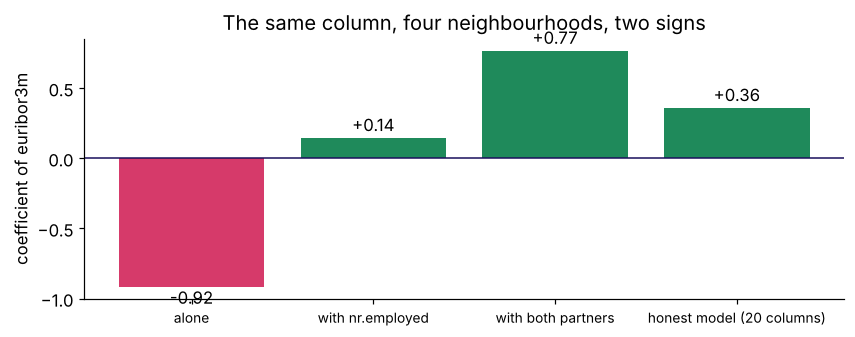

In [4]:
steps = ["alone", "with nr.employed", "with both partners", "honest model (20 columns)"]
vals = [flip.loc["euribor3m", s] for s in steps]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(4), vals, color=[ROSE if v < 0 else GREEN for v in vals])
ax.axhline(0, color=INK, lw=1)
for i, v in enumerate(vals):
    ax.text(i, v + (0.05 if v >= 0 else -0.12), f"{v:+.2f}", ha="center", fontsize=11)
ax.set_xticks(range(4)); ax.set_xticklabels(steps, fontsize=9)
ax.set_ylabel("coefficient of euribor3m"); ax.set_title("The same column, four neighbourhoods, two signs")
plt.tight_layout(); plt.show()

**What happened.** B. Alone, `euribor3m` carries about -0.92. Beside `nr.employed` it turns
to about +0.14, beside both partners about +0.77, and inside the honest model it is about
+0.36. Nothing about interest rates changed between these fits. A coefficient answers "what
changes when this column moves and the others stay fixed", and in this data the partners
never stay fixed, so the credit is split between them almost arbitrarily. The rule: read a
single coefficient's sign only when its column has no close partner; when it has one, read
the group, or ask Thursday's penalty to share the credit. Coefficients are compared only
because every numeric column was standardised first, which is why chapter 2's scaling matters
to a logistic model.

## What does permutation importance rank?
Permutation importance shuffles one column's values across the validation rows, so the
column keeps its spread and loses its link to each client, and measures how far the AUC
falls. A big fall means the fitted model leans on that column.

**Predict before you run.** The top column will be (A) `poutcome`, the strongest single
signal; (B) one of the economic columns; (C) `age`.

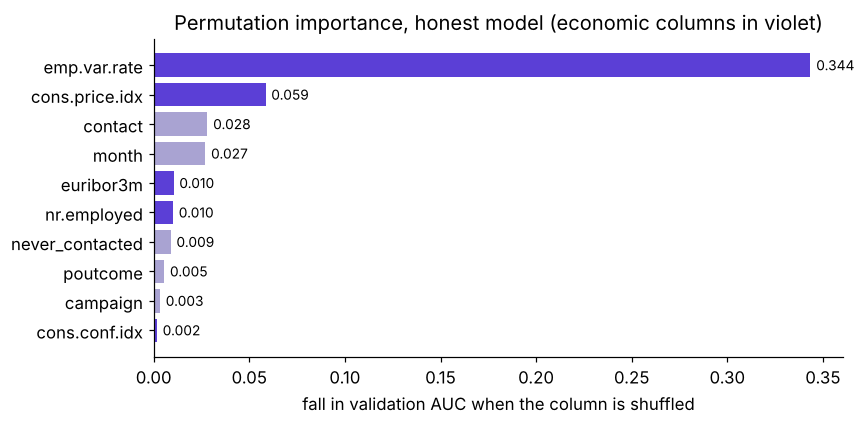

emp.var.rate      0.3435
cons.price.idx    0.0585
contact           0.0281
month             0.0270
euribor3m         0.0104
nr.employed       0.0101


In [5]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(honest_model, val[HONEST], y_val, scoring="roc_auc",
                              n_repeats=5, random_state=42)
imp = pd.Series(perm.importances_mean, index=HONEST).sort_values(ascending=False).round(4)
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top.values, color=[VIOLET if c in ECONOMY else GREY for c in top.index])
for i, x in enumerate(top.values):
    ax.text(x + 0.003, i, f"{x:.3f}", va="center", fontsize=9)
ax.set_xlabel("fall in validation AUC when the column is shuffled")
ax.set_title("Permutation importance, honest model (economic columns in violet)")
plt.tight_layout(); plt.show()
print(imp.head(6).to_string())

**What happened.** B. `emp.var.rate` tops the chart with a fall of about 0.34 in AUC, and
`cons.price.idx` comes second. The client's own history (`poutcome`, `never_contacted`)
sits far below. The ranking says the fitted model leans hardest on the rate columns, which
case 2 showed act as a stamp for the month.

## Why can one column's importance exceed the model's whole lift?
The honest model scores 0.80, so its whole lift above a coin is about 0.30. A single column
whose shuffle costs 0.34 is costing more than the model ever earned. Shuffling
`emp.var.rate` alone builds clients who never existed: a 2010 employment rate beside a 2008
interbank rate. The model's large opposing coefficients on the twins then send those clients
to absurd scores. Shuffling the whole economic group together keeps each row's quarter
consistent and measures what the group carries.

**Predict before you run.** Shuffling all five economic columns together costs (A) more
than 0.34; (B) less than 0.34.

In [6]:
rng = np.random.default_rng(42)
base = roc_auc_score(y_val, honest_model.predict_proba(val[HONEST])[:, 1])
falls = []
for _ in range(5):
    shuffled = val[HONEST].copy()
    idx = rng.permutation(len(shuffled))
    shuffled[ECONOMY] = shuffled[ECONOMY].values[idx]       # one shuffle for the whole group
    falls.append(base - roc_auc_score(y_val, honest_model.predict_proba(shuffled)[:, 1]))
group = float(np.mean(falls))
print(f"model AUC {base:.3f}; lift above a coin {base - 0.5:.3f}")
print(f"emp.var.rate shuffled alone: {imp['emp.var.rate']:.3f}; the five economic columns shuffled together: {group:.3f}")

model AUC 0.795; lift above a coin 0.295
emp.var.rate shuffled alone: 0.344; the five economic columns shuffled together: 0.140


**What happened.** B. Shuffled together, the five columns cost far less than
`emp.var.rate` alone, because each shuffled row is still a real quarter. The rule: when
columns have close partners, permute them as a group; a single-column importance larger
than the model's own lift is the sign that the shuffle built impossible rows.

## Does a top rank prove a cause?
No. The chart ranks how much this fitted model leans on a column when it predicts. It does
not say that moving the column moves the outcome. `nr.employed` ranks high, and hiring more
people in Portugal would not make a client open a deposit: the column stamps the quarter.
`contact` (mobile against landline) ranks in the top ten, and switching every client to a
mobile would not move the yes-rate by the gap the chart suggests, because the clients who
were rung on mobiles differ in other ways. The claim "this lever moves the outcome" needs
Week 1's fair comparison: change the lever for a random group and compare. Kalpa's version:
if `app_visits_7d` topped Kalpa's chart, pushing notifications to raise visits would test the
lever; the chart alone would not.

In [7]:
verdicts = pd.DataFrame([
    ("profile: age, job, marital, education, default, housing, loan", "keep", "known before the call; one-hot and scaled in the pipeline"),
    ("history: contact, month, day_of_week, campaign, previous, poutcome", "keep", "known before the call; poutcome = success converts at 65 percent and passes"),
    ("never_contacted, days_since_contact", "keep (engineered)", "pdays split, since 999 is a sentinel"),
    ("economy: five columns", "keep, flag", "known if published in time; a calendar stamp on a random split; read as a group"),
    ("duration", "drop", "written when the call ends"),
], columns=["feature group", "verdict", "reason"])
print(f"The audited feature set: {len(HONEST)} columns, validation AUC {honest['AUC']}")
verdicts

The audited feature set: 20 columns, validation AUC 0.7955


,feature group,verdict,reason
0,"profile: age, job, marital, education, default...",keep,known before the call; one-hot and scaled in t...
1,"history: contact, month, day_of_week, campaign...",keep,known before the call; poutcome = success conv...
2,"never_contacted, days_since_contact",keep (engineered),"pdays split, since 999 is a sentinel"
3,economy: five columns,"keep, flag",known if published in time; a calendar stamp o...
4,duration,drop,written when the call ends


In [8]:
check("euribor3m is negative alone", flip.loc["euribor3m", "alone"] < 0)
check("euribor3m turns positive beside both partners", flip.loc["euribor3m", "with both partners"] > 0)
check("the top single-column importance exceeds the model's lift above a coin", imp.iloc[0] > base - 0.5)
check("shuffling the economic group together costs less than the top single column", group < imp.iloc[0])
check("the audited set has 20 columns and no duration", len(HONEST) == 20 and "duration" not in HONEST)

PASS  euribor3m is negative alone
PASS  euribor3m turns positive beside both partners
PASS  the top single-column importance exceeds the model's lift above a coin
PASS  shuffling the economic group together costs less than the top single column
PASS  the audited set has 20 columns and no duration


## What do the three cases hand to Thursday?
| Exhibit | What it proves | What it does not |
|---|---|---|
| Validation AUC 0.796 | the honest model ranks calls better than a coin on this split | how it ranks next month; inside a month it is about 0.57 |
| A coefficient's sign | the direction with every other column held fixed | anything, when the column has close partners |
| Permutation importance | how much the fitted model leans on a column | that moving the column moves deposits |

Thursday starts from this audited set of 20 columns and asks whether a more complex model
earns more than it costs.